<a href="https://colab.research.google.com/github/Mittal-Sankalp/Exploratory-Data-Analysis-of-Sentinel-1-SAR-Oil-Spill-Images/blob/main/Exploratory_Data_Analysis_of_Sentinel_1_SAR_Oil_Spill_Images.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Configuring Kaggle API

In [11]:
import os

os.environ['KAGGLE_API_TOKEN'] = 'KGAT_eeda26e5d89a31c060f75af26558110b'

!pip install -q kaggle

print("Kaggle API token configured successfully via environment variable!")

Kaggle API token configured successfully via environment variable!


# Downloading Dataset

In [12]:
!kaggle datasets download -d harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset

!unzip -q sentinel-1-sar-oil-spill-detection-dataset.zip -d ./sentinel_dataset

print("Dataset downloaded and extracted successfully!")

Dataset URL: https://www.kaggle.com/datasets/harikrishnacs/sentinel-1-sar-oil-spill-detection-dataset
License(s): CC-BY-SA-4.0
sentinel-1-sar-oil-spill-detection-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace ./sentinel_dataset/kaggle/data/Class_0/class_0_00001.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace ./sentinel_dataset/kaggle/data/Class_0/class_0_00002.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
Dataset downloaded and extracted successfully!


# Importing Libraries and Extracting Image Statistics

In [16]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set visual style and reproducibility
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

# Point to the unzipped dataset folder
base_dir = './sentinel_dataset'

image_records = []

print(f"Scanning directory: {base_dir} and extracting image statistics...")

for root, dirs, files in os.walk(base_dir):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.tif')):
            filepath = os.path.join(root, file)

            # Get the exact name of the immediate folder containing the image
            folder_name = os.path.basename(root).lower()

            # Strict mapping based on the discovered 'Class_0' and 'Class_1' folder names
            if folder_name == 'class_0':
                label = 'Non-Oil-Spill (0)'
                class_id = 0
            elif folder_name == 'class_1':
                label = 'Oil-Spill (1)'
                class_id = 1
            else:
                continue  # Skip root folders or unclassified directories

            # Read image in grayscale using OpenCV
            img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                image_records.append({
                    'filepath': filepath,
                    'filename': file,
                    'class_id': class_id,
                    'label': label,
                    'height': img.shape[0],
                    'width': img.shape[1],
                    'mean_intensity': np.mean(img),
                    'std_intensity': np.std(img),
                    'min_intensity': np.min(img),
                    'max_intensity': np.max(img)
                })

df = pd.DataFrame(image_records)

# Safety check and summary
if df.empty:
    print("\nERROR: The dataframe is empty. No images were found or classified.")
else:
    print(f"\nTotal Images Processed Successfully: {len(df)}")
    print(df.groupby('label')[['mean_intensity', 'std_intensity']].describe())

Scanning directory: ./sentinel_dataset and extracting image statistics...

Total Images Processed Successfully: 5548
                  mean_intensity                                    \
                           count        mean        std        min   
label                                                                
Non-Oil-Spill (0)         3700.0  137.705879  49.567483   3.931944   
Oil-Spill (1)             1848.0  122.057387  39.290704  34.704325   

                                                                std_intensity  \
                          25%         50%         75%       max         count   
label                                                                           
Non-Oil-Spill (0)  100.152498  138.150491  174.047273  255.0000        3700.0   
Oil-Spill (1)       91.469334  113.927897  147.794630  236.5439        1848.0   

                                                                         \
                        mean        std       min  

# Class Distribution Analysis

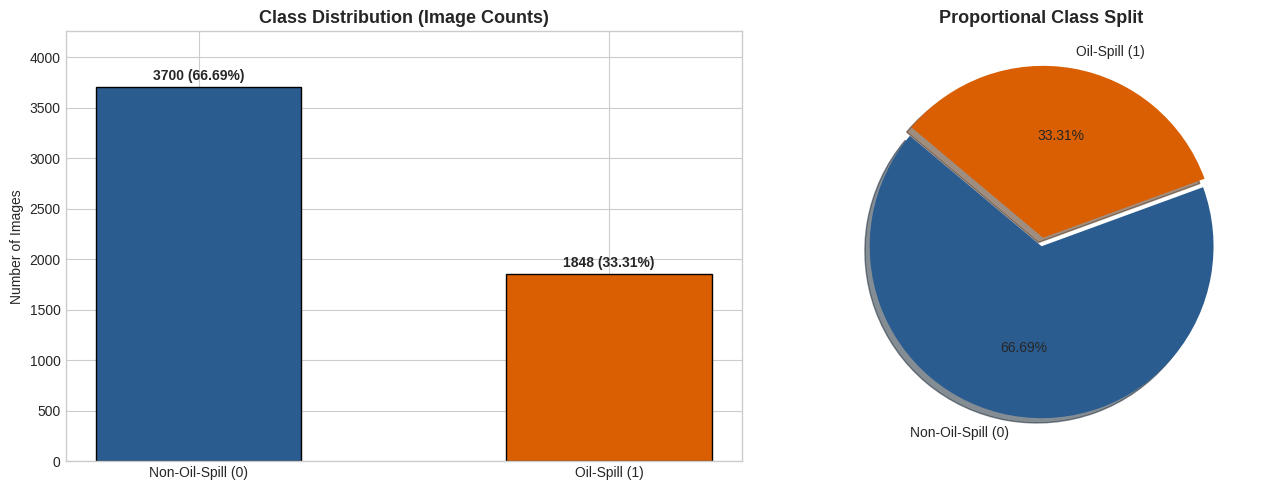

In [17]:
class_counts = df['label'].value_counts()
class_pcts = df['label'].value_counts(normalize=True) * 100

# Safety check in case the dataframe is empty
if len(class_counts) == 0:
    print("Error: No data available to plot. Please check that images were extracted in the previous step.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Dynamically adjust colors and explode based on how many classes were actually found
    colors = ['#2b5c8f', '#d95f02'][:len(class_counts)]

    # If 2 classes exist, explode the second one. If only 1 exists, don't explode.
    explode_tuple = (0, 0.05) if len(class_counts) == 2 else tuple([0] * len(class_counts))

    # Bar Chart
    bars = axes[0].bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', width=0.5)
    axes[0].set_title('Class Distribution (Image Counts)', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Number of Images')
    for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + (max(class_counts.values)*0.02),
                     f'{count} ({pct:.2f}%)', ha='center', fontweight='bold')
    axes[0].set_ylim(0, max(class_counts.values) * 1.15)

    # Pie Chart
    axes[1].pie(class_counts.values, labels=class_counts.index, autopct='%1.2f%%',
                colors=colors, startangle=140, explode=explode_tuple, shadow=True)
    axes[1].set_title('Proportional Class Split', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.savefig('class_distribution.png', dpi=300)
    plt.show()

# Image Visualization & Intensity Extremes

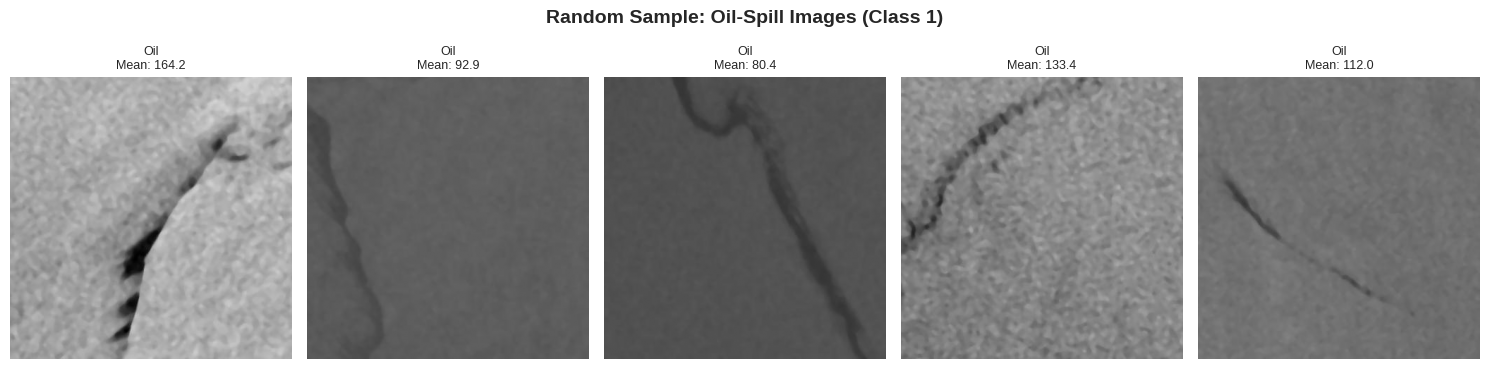

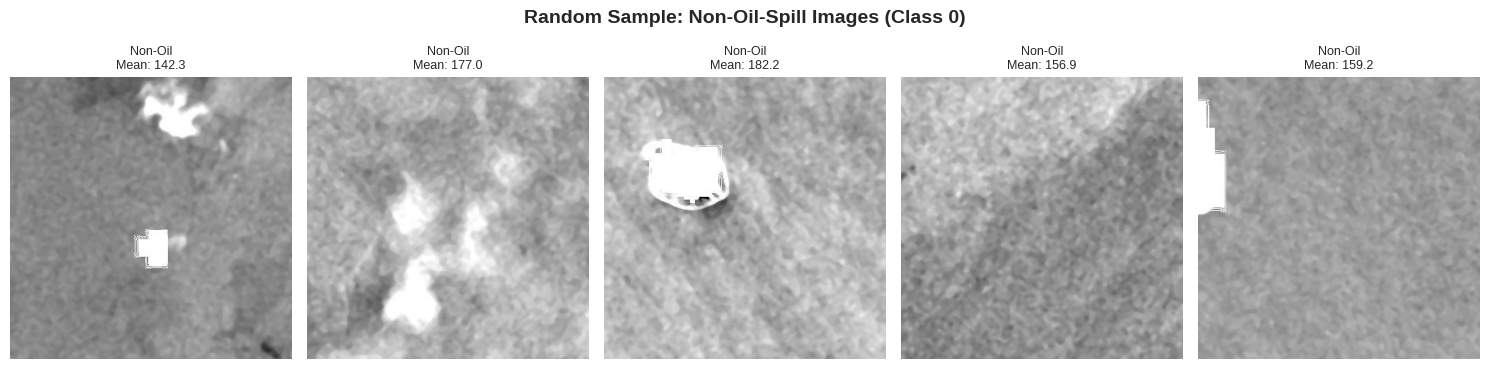

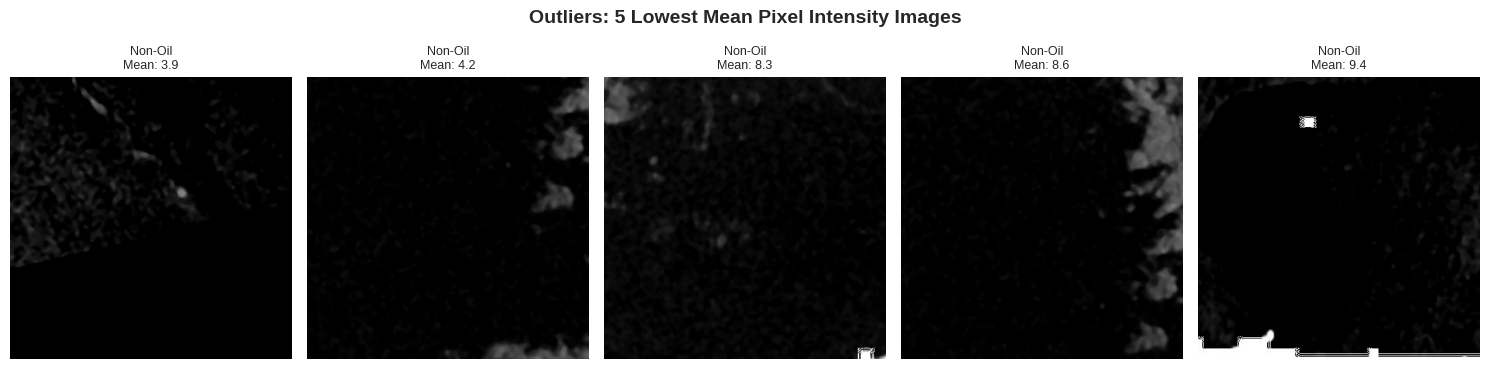

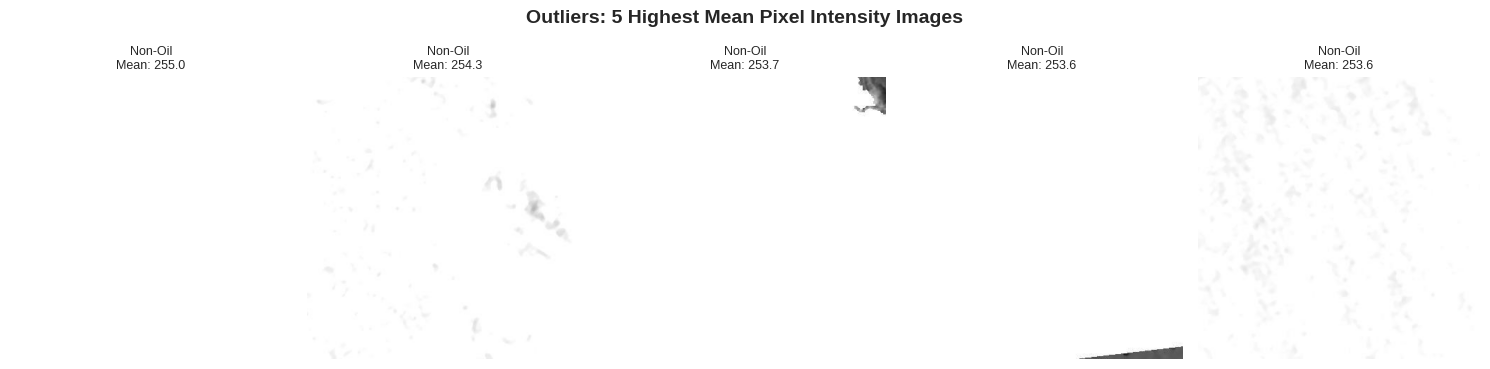

In [18]:
def plot_image_grid(sub_df, title, n_cols=5):
    fig, axes = plt.subplots(1, n_cols, figsize=(15, 3.5))
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.05)

    if n_cols == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sub_df.iterrows()):
        img = cv2.imread(row['filepath'], cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap='gray', vmin=0, vmax=255)
        short_label = 'Oil' if row['class_id'] == 1 else 'Non-Oil'
        ax.set_title(f"{short_label}\nMean: {row['mean_intensity']:.1f}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Display random grids
if len(df[df['class_id'] == 1]) >= 5:
    plot_image_grid(df[df['class_id'] == 1].sample(5), "Random Sample: Oil-Spill Images (Class 1)")
if len(df[df['class_id'] == 0]) >= 5:
    plot_image_grid(df[df['class_id'] == 0].sample(5), "Random Sample: Non-Oil-Spill Images (Class 0)")

# Display extreme pixel intensity outliers
lowest_intensity = df.nsmallest(5, 'mean_intensity')
highest_intensity = df.nlargest(5, 'mean_intensity')

plot_image_grid(lowest_intensity, "Outliers: 5 Lowest Mean Pixel Intensity Images")
plot_image_grid(highest_intensity, "Outliers: 5 Highest Mean Pixel Intensity Images")

# Statistical Outlier Detection

/tmp/ipykernel_898/1280289556.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 0].boxplot(box_data, patch_artist=True, labels=['Non-Oil-Spill (0)', 'Oil-Spill (1)'])


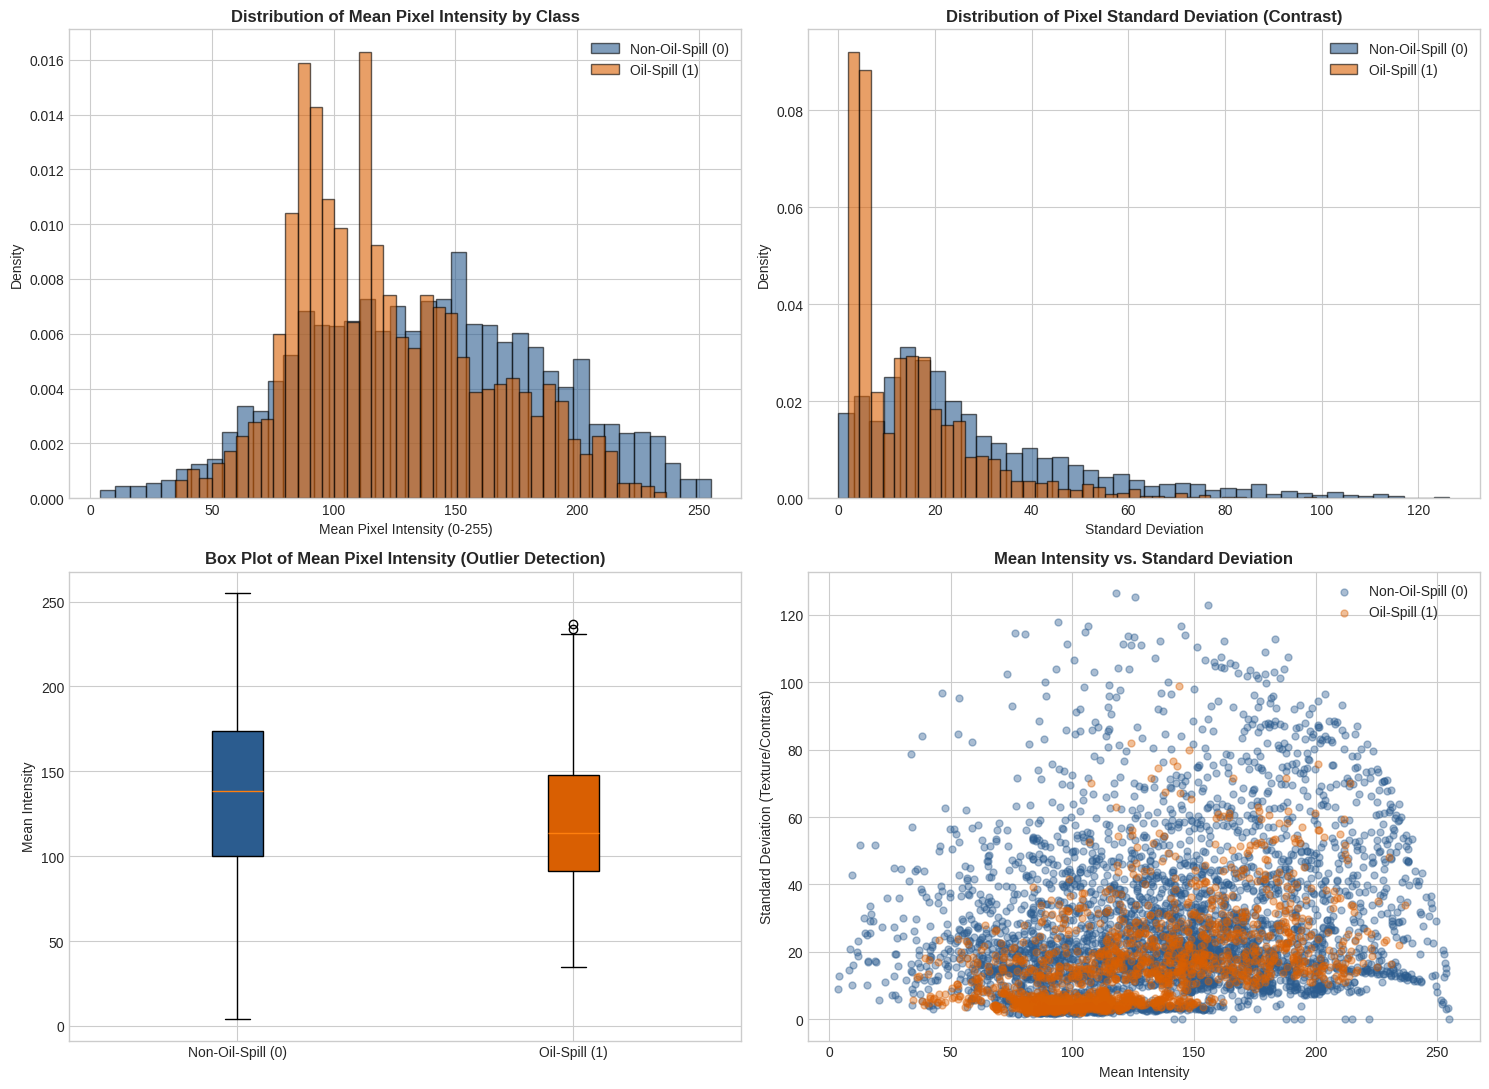


--- IQR OUTLIER SUMMARY REPORT ---
Non-Oil-Spill (0) -> Q1: 100.15, Q3: 174.05, IQR Bounds: [-10.69, 284.89] | Outliers Detected: 0
Oil-Spill (1) -> Q1: 91.47, Q3: 147.79, IQR Bounds: [6.98, 232.28] | Outliers Detected: 2


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

df_no_oil = df[df['class_id'] == 0]
df_oil = df[df['class_id'] == 1]

# 1. Mean Intensity Histogram
axes[0, 0].hist(df_no_oil['mean_intensity'], bins=40, alpha=0.6, label='Non-Oil-Spill (0)', color='#2b5c8f', edgecolor='black', density=True)
axes[0, 0].hist(df_oil['mean_intensity'], bins=40, alpha=0.6, label='Oil-Spill (1)', color='#d95f02', edgecolor='black', density=True)
axes[0, 0].set_title('Distribution of Mean Pixel Intensity by Class', fontweight='bold')
axes[0, 0].set_xlabel('Mean Pixel Intensity (0-255)')
axes[0, 0].set_ylabel('Density')
axes[0, 0].legend()

# 2. Standard Deviation Histogram
axes[0, 1].hist(df_no_oil['std_intensity'], bins=40, alpha=0.6, label='Non-Oil-Spill (0)', color='#2b5c8f', edgecolor='black', density=True)
axes[0, 1].hist(df_oil['std_intensity'], bins=40, alpha=0.6, label='Oil-Spill (1)', color='#d95f02', edgecolor='black', density=True)
axes[0, 1].set_title('Distribution of Pixel Standard Deviation (Contrast)', fontweight='bold')
axes[0, 1].set_xlabel('Standard Deviation')
axes[0, 1].set_ylabel('Density')
axes[0, 1].legend()

# 3. Box Plots for Outlier Detection
box_data = [df_no_oil['mean_intensity'], df_oil['mean_intensity']]
bp = axes[1, 0].boxplot(box_data, patch_artist=True, labels=['Non-Oil-Spill (0)', 'Oil-Spill (1)'])
bp['boxes'][0].set_facecolor('#2b5c8f')
bp['boxes'][1].set_facecolor('#d95f02')
axes[1, 0].set_title('Box Plot of Mean Pixel Intensity (Outlier Detection)', fontweight='bold')
axes[1, 0].set_ylabel('Mean Intensity')

# 4. Scatter Plot: Mean vs Standard Deviation
axes[1, 1].scatter(df_no_oil['mean_intensity'], df_no_oil['std_intensity'], alpha=0.4, label='Non-Oil-Spill (0)', color='#2b5c8f', s=25)
axes[1, 1].scatter(df_oil['mean_intensity'], df_oil['std_intensity'], alpha=0.4, label='Oil-Spill (1)', color='#d95f02', s=25)
axes[1, 1].set_title('Mean Intensity vs. Standard Deviation', fontweight='bold')
axes[1, 1].set_xlabel('Mean Intensity')
axes[1, 1].set_ylabel('Standard Deviation (Texture/Contrast)')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('image_statistics_outliers_matplotlib.png', dpi=300)
plt.show()

print("\n--- IQR OUTLIER SUMMARY REPORT ---")
for label, group in df.groupby('label'):
    q1 = group['mean_intensity'].quantile(0.25)
    q3 = group['mean_intensity'].quantile(0.75)
    iqr = q3 - q1
    low_bound = q1 - 1.5 * iqr
    high_bound = q3 + 1.5 * iqr
    outliers = group[(group['mean_intensity'] < low_bound) | (group['mean_intensity'] > high_bound)]
    print(f"{label} -> Q1: {q1:.2f}, Q3: {q3:.2f}, IQR Bounds: [{low_bound:.2f}, {high_bound:.2f}] | Outliers Detected: {len(outliers)}")